# Notebook 14: Identical Particles, or When Does Γ Know the Statistics?

**Goal:** Bosons, fermions and distinguishable particles moved by the same single-particle dynamics give different Γ. Find *where* in Γ the difference lives, and which
part of it survives division events.

By the end of this notebook you will be able to:
- Build Γ on occupation configurations for bosons (permanents), fermions (determinants) and distinguishable particles, and read the Hong–Ou–Mandel effect off one column
- Show that for two particles $\Gamma_D = (\Gamma_B + \Gamma_F)/2$ exactly, which isolates an exchange-interference term
- Show that the statistics has two parts that scale differently in time: an occupation rule (Pauli exclusion, Bose enhancement) and exchange interference
- Show that dense division events erase the interference but keep the occupation rule, turning the three processes into classical exclusion, inclusion and independent random walks,
  whose stationary states are Fermi–Dirac, Bose–Einstein and Maxwell–Boltzmann counting
- Show that the fermion sign around a ring is pure interference: records make fermions and hard-core bosons identical

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

---
> ### 📓 Annotated study copy
>
> Study copy of `14_identical_particles.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-10-25 from the identical-particles spike (`notes/identical-particles-spike-2026-10-25.md`), item 4 of the textbook backlog
> (`notes/textbook-concepts-backlog-2026-10-24.md`), prompted by Griffiths §5.1.2 ("exchange forces") and Peskin §9.5 (Grassmann numbers). The question: *when does Γ know whether
> the particles are bosons, fermions or distinguishable, and what part of that knowledge survives division events?* Short answer: Γ generically knows (not for every $U$: a pure permutation of sites hides it); the occupation rule survives
> records, the exchange interference does not.
>
> **Prior work.** The pieces are known: Hong–Ou–Mandel (1987); the inclusion process (Giardinà, Kurchan and Redig (2007)); dephased free particles becoming exclusion and
> inclusion processes (Yamaga (2020); Wellnitz et al. (2022), App. E); uniform Haar landing of bosons, behind the bosonic birthday paradox (Aaronson and Arkhipov (2011), §13; Arkhipov and Kuperberg (2012)). The notebook restates them in Γ
> language (see the 🔭 cell at the end).
>
> Right after this banner: a summary of what Γ explains here and what it doesn't.
---

### 📖 In depth: what Γ explains about quantum statistics, and what it doesn't

**What Γ explains**
- **Where the statistics shows up.** In one column for Hong–Ou–Mandel (section 1); in an exact two-particle split into an average and an exchange term (section 2).
- **That "statistics" is two things.** An occupation rule, which is a Markov property of the configurations, and exchange interference, which is indivisible (sections 3, 4 and 6).
- **Where the textbook counting comes from.** The stationary states of the recorded processes are Bose–Einstein, Fermi–Dirac and Maxwell–Boltzmann counting (section 5).

**What Γ does not explain**
- **Why particles are bosons or fermions.** That is input here (permanent vs determinant). The spin–statistics connection is outside Γ.
- **The sign itself.** Γ sees the fermion sign only through interference over an indivisible stretch; the sign lives in the amplitudes.
- **Interactions and energy.** These are free particles on equal-energy sites; thermal (canonical) counting would need energies and a bath.

**Net.** The part of the statistics that survives division events is counting: which occupations exist and how fast they are entered. The rest is interference.

<!-- expansion:14:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** Textbooks introduce identical particles through symmetric and antisymmetric wave functions, then talk about an "exchange force" that is "not really a force".
This notebook asks what the statistics look like in Γ, the transition probabilities between configurations, and which part of them survives when the configurations are recorded often.

**Prerequisites.**
- Notebook 03: indivisibility.
- Notebook 06: division events (records).
- Notebook 11: dense division events and the Zeno limit, $\Gamma(\tau)^n$ with $\Gamma(\tau) - I \propto \tau^2$.
- Notebook 12: the fermion sign on a ring (Jordan–Wigner) and why hard-core bosons equal fermions on an open chain.
- No prior knowledge of permanents or second quantization; the 📘 and 🧮 cells cover what is needed.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*. The first code cell imports from `isp/identical.py` and `isp/wick.py`, so `isp/` must sit next to `notebooks/`.
Needs numpy, scipy and matplotlib. It runs in under a minute; section 5 (2,000 random unitaries) is the slowest.

**Search-engineer framing.** Deduplicated logs count users per page without knowing who is who. Crowding effects (a page that attracts more visitors when busy, or a slot that holds only
one) still show in such logs, even if sampled constantly. Effects that depend on two users' paths being indistinguishable alternatives do not survive frequent sampling.


<!-- expansion:14:glossary -->
### 📘 Glossary

- **Occupation configuration $m = (m_0, \dots, m_{N-1})$.** How many particles are on each site. The only thing a detector that cannot tell particles apart can record.
- **Boson / fermion / distinguishable.** Bosons can share sites and prefer to; fermions never share (Pauli exclusion); distinguishable particles ignore each other but carry labels,
  which the occupation record forgets.
- **Permanent.** Like a determinant but with every sign $+$. Boson amplitudes are permanents of submatrices of $U$; fermion amplitudes are determinants.
- **Exchange term $X$.** For two particles, $X = \Gamma_B - \Gamma_D = \Gamma_D - \Gamma_F$: the interference between "A here, B there" and the swapped story.
- **Occupation rule.** The rate factor for a particle hopping from site $i$ to site $j$: $m_i(m_j+1)$ for bosons, $m_i(1-m_j)$ for fermions, $m_i$ for distinguishable particles.
- **Hong–Ou–Mandel (HOM) effect.** Two identical bosons entering a 50:50 beam splitter from different sides always leave together.
- **Exclusion / inclusion process.** Classical Markov chains of particles hopping on a lattice with the fermion / boson occupation rule. Independent random walkers are the distinguishable case.
- **Bose–Einstein / Fermi–Dirac / Maxwell–Boltzmann counting.** Every occupation pattern equally likely (bosons); every pattern without doubles equally likely (fermions); every
  *labelled* arrangement equally likely, which weights occupation patterns by a multinomial (distinguishable).
- **Hard-core bosons.** Bosons that cannot share a site: fermions' occupation rule without the fermion sign.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.stats import unitary_group
from isp.identical import gamma, configurations, classical_generator, stationary, chain, embed
from isp.wick import two_particle_hamiltonian

### 📖 In depth: the idea in plain words

- **Identical particles.** If two particles cannot be told apart, a detector records only how many are on each site. Those occupation counts are the configurations.
- **Three rules.** Bosons are happy to share a site, and more likely to join a crowded one. Fermions never share. Distinguishable particles ignore each other.
- **Two ways the rules show up.** One is a rule about *which* configurations exist and *how fast* they are entered: you can see it even if you look at the particles constantly. The
  other is interference between "particle A went here and B there" and the swapped story: you only see it if you leave the particles alone for a while.
- **What records do.** Looking constantly (division events) kills the interference but leaves the rule. Bosons still bunch, fermions still never share, but the Hong–Ou–Mandel dip
  and the fermion sign around a ring disappear.
- **For a search engineer.** Deduplicated logs (you count users per page, not which user) still show crowding effects if the system has a crowding rule; they lose any effect that
  depends on two users' paths being indistinguishable alternatives.

## 1. Configurations Are Occupations

A detector that cannot tell the particles apart records how many are on each site: an occupation tuple such as $(1, 1)$ or $(2, 0)$. That is the configuration. Every particle is moved by the same
single-particle unitary $U$, and Γ on occupations is:
- **bosons:** $|\mathrm{perm}\,U_{\rm sub}|^2$ divided by the occupation factorials;
- **fermions:** $|\det U_{\rm sub}|^2$ (at most one per site);
- **distinguishable:** independent walkers with the labels forgotten, $\mathrm{perm}(|U_{\rm sub}|^2)$ divided by the factorials of the final occupations.

The test case: a 50:50 beam splitter, one particle in each input. This is the Hong–Ou–Mandel experiment.

<!-- expansion:14:books-griffiths -->
### 📚 From the books: Griffiths on the exchange force, Peskin on Grassmann numbers

- **Griffiths**, *Introduction to Quantum Mechanics*, §5.1.2 "Exchange Forces" (printed p. 184): the system "behaves as though there were a 'force of attraction' between identical bosons,
  pulling them closer together, and a 'force of repulsion' between identical fermions, pushing them apart. We call it an exchange force, although it's not really a force at
  all—no physical agency is pushing on the particles; rather, it is a purely geometrical consequence of the symmetrization requirement."
- **Griffiths**, §5.4.3 "The Most Probable Configuration" (printed p. 209): "In thermal equilibrium, every state with a given total energy E and a given particle number N is equally likely."
- **Peskin & Schroeder**, *An Introduction to Quantum Field Theory*, §9.5 (printed p. 299), on anticommuting (Grassmann) numbers: "These rules are formal and might seem ad hoc."

This notebook makes Griffiths' "not really a force" concrete: what survives records is a rule about configurations. It also shows how little of the fermion machinery Γ needs:
an occupation rule plus a sign that only indivisible stretches see.


In [2]:
BS = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)          # 50:50 beam splitter on two modes
for kind in ["boson", "distinguishable", "fermion"]:
    G, C = gamma(BS, 2, kind)
    col = G[:, C.index((1, 1))]
    print(f"{kind:16s} columns sum to 1: {np.allclose(G.sum(axis=0), 1)}   from (1,1): "
          + ",  ".join(f"{c} {p:.2f}" for c, p in zip(C, col)))

boson            columns sum to 1: True   from (1,1): (2, 0) 0.50,  (1, 1) 0.00,  (0, 2) 0.50
distinguishable  columns sum to 1: True   from (1,1): (2, 0) 0.25,  (1, 1) 0.50,  (0, 2) 0.25
fermion          columns sum to 1: True   from (1,1): (1, 1) 1.00


### 🔍 Reading the code

- **`gamma(BS, 2, kind)`** returns Γ for two particles on the two output modes, and the list of configurations in row/column order: `(2, 0)`, `(1, 1)`, `(0, 2)` for bosons and
  distinguishable particles, only `(1, 1)` for fermions.
- **`col`** is the column for the input $(1, 1)$: the probabilities of each output.
- **Bosons:** the two "both transmitted" and "both reflected" amplitudes cancel, so $(1,1)$ never happens: the Hong–Ou–Mandel dip. **Fermions** can only end in $(1,1)$. **Distinguishable**
  particles go each way independently.

<!-- expansion:14:derive-beam-splitter -->
### 🧮 Worked derivation: the 2 × 2 beam splitter by hand

$U = \frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$. Input $(1,1)$: one particle in each mode. The submatrix for output $(1,1)$ is all of $U$.
- **Bosons:** $\mathrm{perm}\,U = U_{00}U_{11} + U_{01}U_{10} = \tfrac12(1 + i^2) = 0$. Coincidence 0.
- **Fermions:** $\det U = \tfrac12(1 - i^2) = 1$. Coincidence 1.
- **Distinguishable:** $\mathrm{perm}|U|^2 = \tfrac14 + \tfrac14 = \tfrac12$.
- **Output $(2,0)$ for bosons:** rows $(0,0)$, columns $(0,1)$: $\mathrm{perm} = 2U_{00}U_{01} = i$, so $|i|^2/2! = 1/2$.

The "both transmitted" and "both reflected" stories have amplitudes $\tfrac12$ and $\tfrac{i^2}{2} = -\tfrac12$: they cancel for bosons and reinforce for fermions.


## 2. Distinguishable = the Average of Bosons and Fermions

For two particles there is an exact identity, entry by entry and for any $U$: $\Gamma_D = (\Gamma_B + \Gamma_F)/2$ on every column that starts from two distinct sites.
Rows may be doubly occupied (there $\Gamma_F = 0$). Columns that start doubly occupied are outside it: fermions cannot start there, so $\Gamma_F$ has no such column (the code checks
distinct-site columns only). On that domain bosons and fermions sit symmetrically on either side of distinguishable particles,

$$\Gamma_B = \Gamma_D + X, \qquad \Gamma_F = \Gamma_D - X,$$

and $X$, the **exchange term**, holds all of the difference between them. (This is the parallelogram law $|a+b|^2+|a-b|^2=2|a|^2+2|b|^2$ applied to the two stories,
standard in two-photon interference.)

<!-- expansion:14:recap-1 -->
### 📝 Recap: section 1

- Configurations are occupations; Γ is built from permanents (bosons), determinants (fermions) or products of probabilities (distinguishable).
- The Hong–Ou–Mandel effect is one column of Γ: coincidence 0, 1/2, 1.


In [3]:
U = unitary_group.rvs(4, random_state=7)
GB, CB = gamma(U, 2, "boson"); GF, CF = gamma(U, 2, "fermion"); GD, _ = gamma(U, 2, "distinguishable")
GF_big = embed(GF, CF, CB)                              # fermion Γ placed among the boson configurations
distinct = [b for b, c in enumerate(CB) if max(c) == 1]
print(f"two particles, random 4-site U:   max |Γ_D − (Γ_B + Γ_F)/2| = "
      f"{np.abs(GD - (GB + GF_big) / 2)[:, distinct].max():.1e}")
X = (GB - GF_big) / 2
print(f"size of the exchange term X:      max |X| = {np.abs(X[:, distinct]).max():.3f}")

U3 = unitary_group.rvs(4, random_state=8)
GB3, C3 = gamma(U3, 3, "boson"); GF3, CF3 = gamma(U3, 3, "fermion"); GD3, _ = gamma(U3, 3, "distinguishable")
dist3 = [b for b, c in enumerate(C3) if max(c) == 1]
print(f"three particles:                  max |Γ_D − (Γ_B + Γ_F)/2| = "
      f"{np.abs(GD3 - (GB3 + embed(GF3, CF3, C3)) / 2)[:, dist3].max():.3f}   (the identity is two-particle only)")

two particles, random 4-site U:   max |Γ_D − (Γ_B + Γ_F)/2| = 2.2e-16
size of the exchange term X:      max |X| = 0.253
three particles:                  max |Γ_D − (Γ_B + Γ_F)/2| = 0.134   (the identity is two-particle only)


### 📖 In depth: why distinguishable is the average

Two particles start on sites $k \neq l$ and end on $i \neq j$. There are two stories: $k\to i, l\to j$ (amplitude $a = U_{ik}U_{jl}$) and $k\to j, l\to i$ (amplitude $b = U_{jk}U_{il}$).
- Bosons add them: $|a+b|^2$. Fermions subtract: $|a-b|^2$. Distinguishable particles, whose labels are then forgotten, add probabilities: $|a|^2 + |b|^2$.
- $|a+b|^2 + |a-b|^2 = 2(|a|^2 + |b|^2)$, so $\Gamma_D = (\Gamma_B + \Gamma_F)/2$. The exchange term is $X = 2\,\mathrm{Re}(a\bar b)$.
- Ending on one site $i$: bosons $2|U_{ik}U_{il}|^2$, distinguishable $|U_{ik}U_{il}|^2$, fermions 0. Again the average.
- Starting both on one site $k$: there is only one story, so bosons and distinguishable particles agree ($\Gamma_B = \Gamma_D$ on that column), and fermions cannot start there at all.
  The identity is a statement about columns that start on distinct sites.

With three particles there are six stories and the bosonic and fermionic sums involve different sign patterns over them; the simple average fails.

<!-- expansion:14:recap-2 -->
### 📝 Recap: section 2

- For two particles, $\Gamma_D = (\Gamma_B + \Gamma_F)/2$ exactly, for any $U$, on every column that starts from two distinct sites (fermions have no doubly occupied columns).
- So $\Gamma_B = \Gamma_D + X$ and $\Gamma_F = \Gamma_D - X$: the exchange term $X$ holds the whole difference.
- With three particles the identity fails.


## 3. Two Parts of the Statistics

Put two particles on a 4-site chain with nearest-neighbour hopping, $U = e^{-ih\tau}$, and look at short times. Two kinds of entries differ between the statistics:
- **Joining an occupied site**, e.g. $(1,1,0,0) \to (2,0,0,0)$: bosons get twice the distinguishable value, fermions get zero. This is the occupation rule: Bose enhancement and Pauli exclusion.
- **Moving between configurations with distinct sites**, e.g. $(1,1,0,0) \to (1,0,1,0)$: here the statistics enter only through the exchange term $X$.

Compare how fast each grows with $\tau$. The hopping here is real. The last lines repeat the exchange-term slope on rings with a flux Φ threaded through them, where the hopping is complex.

τ = 0.010:  hop 1.00e-04   join: boson/distinguishable = 2.000, fermion 0e+00   exchange |X| = 1.00e-08  (|X| / hop = 1.0e-04)
τ = 0.066:  hop 4.29e-03   join: boson/distinguishable = 2.000, fermion 0e+00   exchange |X| = 1.86e-05  (|X| / hop = 4.3e-03)
τ = 0.316:  hop 8.19e-02   join: boson/distinguishable = 2.000, fermion 0e+00   exchange |X| = 8.52e-03  (|X| / hop = 1.0e-01)

log-log slopes:  hop 1.96   boson join 1.97   exchange |X| 3.97
exchange |X| slope on rings with flux Φ = 0, π/3, π/2, π:
  3-site ring:  3.97   2.99   2.98   3.97
  4-site ring:  3.94   3.94   3.94   3.97


  5-site ring:  3.95   3.97   3.98   3.95


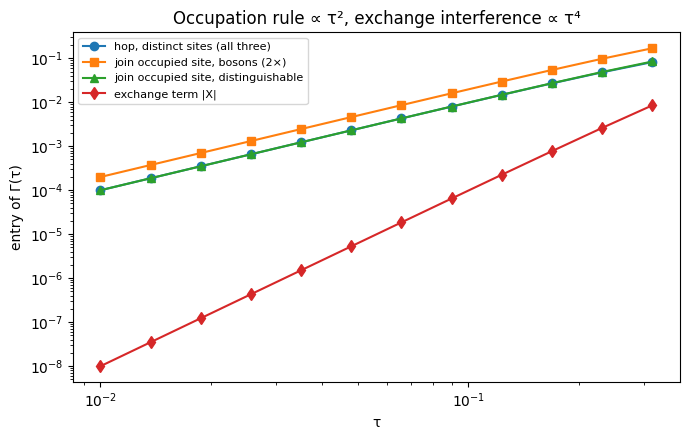

In [4]:
h = chain(4)
C = configurations(4, 2, "boson")
start, join, move = C.index((1, 1, 0, 0)), C.index((2, 0, 0, 0)), C.index((1, 0, 1, 0))
dis = [k for k, c in enumerate(C) if max(c) == 1]

taus = np.logspace(-2, -0.5, 12)
rows = []
for tau in taus:
    U = expm(-1j * h * tau)
    GB, _ = gamma(U, 2, "boson"); GD, _ = gamma(U, 2, "distinguishable")
    GF, CF = gamma(U, 2, "fermion"); GF = embed(GF, CF, C)
    Xd = ((GB - GF) / 2)[np.ix_(dis, dis)].copy(); np.fill_diagonal(Xd, 0)
    rows.append((GD[move, start], GB[join, start], GD[join, start], GF[join, start], np.abs(Xd).max()))
rows = np.array(rows)

for tau, r in zip(taus[[0, 6, 11]], rows[[0, 6, 11]]):
    print(f"τ = {tau:.3f}:  hop {r[0]:.2e}   join: boson/distinguishable = {r[1] / r[2]:.3f}, fermion {r[3]:.0e}"
          f"   exchange |X| = {r[4]:.2e}  (|X| / hop = {r[4] / r[0]:.1e})")
slope = lambda y: np.polyfit(np.log(taus), np.log(y), 1)[0]
print(f"\nlog-log slopes:  hop {slope(rows[:, 0]):.2f}   boson join {slope(rows[:, 1]):.2f}   exchange |X| {slope(rows[:, 4]):.2f}")

def flux_ring(N, phi):                                  # N-site ring with flux phi threaded through it (phase on the closing bond)
    hr = chain(N, ring=True).astype(complex)
    hr[0, N - 1] *= np.exp(1j * phi); hr[N - 1, 0] = np.conj(hr[0, N - 1])
    return hr

def x_slope(hh):
    Cr = configurations(len(hh), 2, "boson"); dr = [k for k, c in enumerate(Cr) if max(c) == 1]; xs = []
    for t in taus:
        Ut = expm(-1j * hh * t); GBr, _ = gamma(Ut, 2, "boson"); GFr, CFr = gamma(Ut, 2, "fermion")
        Xr = ((GBr - embed(GFr, CFr, Cr)) / 2)[np.ix_(dr, dr)].copy(); np.fill_diagonal(Xr, 0); xs.append(np.abs(Xr).max())
    return slope(np.array(xs))

print("exchange |X| slope on rings with flux Φ = 0, π/3, π/2, π:")
for N in [3, 4, 5]:
    print(f"  {N}-site ring:  " + "   ".join(f"{x_slope(flux_ring(N, phi)):.2f}" for phi in [0, np.pi / 3, np.pi / 2, np.pi]))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(taus, rows[:, 0], 'o-', label='hop, distinct sites (all three)')
ax.loglog(taus, rows[:, 1], 's-', label='join occupied site, bosons (2×)')
ax.loglog(taus, rows[:, 2], '^-', label='join occupied site, distinguishable')
ax.loglog(taus, rows[:, 4], 'd-', label='exchange term |X|')
ax.set_xlabel('τ'); ax.set_ylabel('entry of Γ(τ)'); ax.set_title('Occupation rule ∝ τ², exchange interference ∝ τ⁴'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 📖 In depth: why the exchange term is so small at short times

Over a short step, $U \approx 1 - ih\tau - h^2\tau^2/2$. Take one particle hopping $k \to i$ while the other stays at $l$: the direct story has amplitude $\approx -ih_{ik}\tau$. The swapped
story needs the particle at $k$ to reach $l$ *and* the one at $l$ to reach $i$: two moves of at least one hop each, so its amplitude is at most of order $\tau^2$. On a chain $k$, $l$ and $i$ cannot all be
neighbours, so the swapped story is $\tau^3$ and $X$ is $\tau \cdot \tau^3 = \tau^4$ directly, while the hop itself is $\tau^2$. On a graph with triangles the swapped story is
$\tau^2$, so $X$ has a $\tau^3$ piece, which is $i$ times a real number (so its real part vanishes) when the hopping is real.

The $\tau^3$ piece survives only when $k$, $l$ and $i$ form a triangle threaded by a flux Φ: then $\mathrm{Re}\,X \propto \tau^3 \sin\Phi$. The ring printout shows it: slope 3 on the
triangle at Φ = π/3 and π/2, slope 4 at Φ = 0 and π (where the hopping is real again) and on the 4- and 5-site rings, which have no 3-site loop.

Joining an occupied site is different: both stories end in the same place and have the *same* amplitude, so they always add in phase. That is where the factor 2 (Bose) or 0 (Pauli)
comes from, and it appears already at order $\tau^2$. The diagonal entry is the exception to "in phase": there the two stories have very different sizes, and $X$ is order
$\tau^2$ but *negative* for bosons (on the 4-site chain at $\tau = 0.05$, staying at $(1,1,0,0)$: bosons 0.988 < distinguishable 0.993 < fermions 0.998). That sign is forced by
probability conservation: each column of $X$ sums to zero, so the positive join rows must be paid for on the diagonal.

<!-- expansion:14:recap-3 -->
### 📝 Recap: section 3

- Joining an occupied site: bosons exactly 2× distinguishable, fermions 0, already at order $\tau^2$.
- Exchange interference between different distinct-site configurations (off-diagonal): order $\tau^4$, or $\tau^3$ (∝ sin Φ) when a flux Φ threads a 3-site loop. On the join rows the
  exchange term is the $\tau^2$ rule itself (always constructive).
- Two parts of the statistics, separated by how fast they grow.


## 4. Division Events Keep the Occupation Rule and Erase the Interference

Record the occupations every $\tau$: Barandes's division events (Paper 3 §2.2), taken dense as in notebook 11. Over a stretch $s/\tau^2$ steps long, entries of order $\tau^2$ add up to a finite rate and entries of order $\tau^4$ vanish, so
$\Gamma(\tau)^{s/\tau^2} \to e^{sL}$, where $L$ is a classical Markov generator: each particle hops at rate $|h_{ji}|^2$, times $m_j + 1$ for bosons (the *inclusion process*), times $1 - m_j$ for fermions
(the *exclusion process*), and times 1 for distinguishable particles (independent walkers).

Then watch the Hong–Ou–Mandel coincidence on two sites, with and without records. With records the coincidence relaxes to the stationary values 1/3, 1/2, 1 (section 5);
bosons still bunch (1/3 < 1/2).

<!-- expansion:14:derive-rate -->
### 🧮 Worked derivation: why records turn Γ into a Markov rate

From notebook 11: with division events (Barandes, Paper 3 §2.2) every $\tau$, the process over a long stretch is $\Gamma(\tau)^n$. Write $\Gamma(\tau) = I + \tau^2 A + \tau^4 B + \dots$. With $n = s/\tau^2$,

$$\Gamma(\tau)^{s/\tau^2} = \left(I + \tau^2 A + O(\tau^4)\right)^{s/\tau^2} \to e^{sA}, \qquad \tau \to 0 .$$

The $\tau^4$ part, including the off-diagonal exchange term, contributes $s\tau^2 \to 0$. (With a flux through a 3-site loop the exchange term is $\tau^3$; it then contributes $s\tau \to 0$, and the limit is the same.) The rate matrix $A$ has off-diagonal entries $|H_{mn}|^2$, the squared many-body hopping amplitudes. For a particle
hopping from $i$ to $j$ these are $|h_{ji}|^2$ times $m_i(m_j+1)$ (bosons, from $a_j^\dagger a_i$ acting on occupations), $m_i(1-m_j)$ (fermions), or $m_i$ (each labelled particle hops
independently). The printed errors fall by about 4 each time $\tau$ halves: the $O(\tau^2)$ correction.


max |Γ(τ)^(s/τ²) − exp(sL)| on the 4-site chain, s = 0.6
  boson            τ = 0.1, 0.05, 0.025:  1.4e-03   3.5e-04   8.6e-05
  distinguishable  τ = 0.1, 0.05, 0.025:  1.4e-03   3.4e-04   8.5e-05
  fermion          τ = 0.1, 0.05, 0.025:  1.6e-03   4.1e-04   1.0e-04
boson           : coincidence at t = π/4 without records 0.000;  with records every τ = 0.1, after 300 steps 0.333
distinguishable : coincidence at t = π/4 without records 0.500;  with records every τ = 0.1, after 300 steps 0.500
fermion         : coincidence at t = π/4 without records 1.000;  with records every τ = 0.1, after 300 steps 1.000


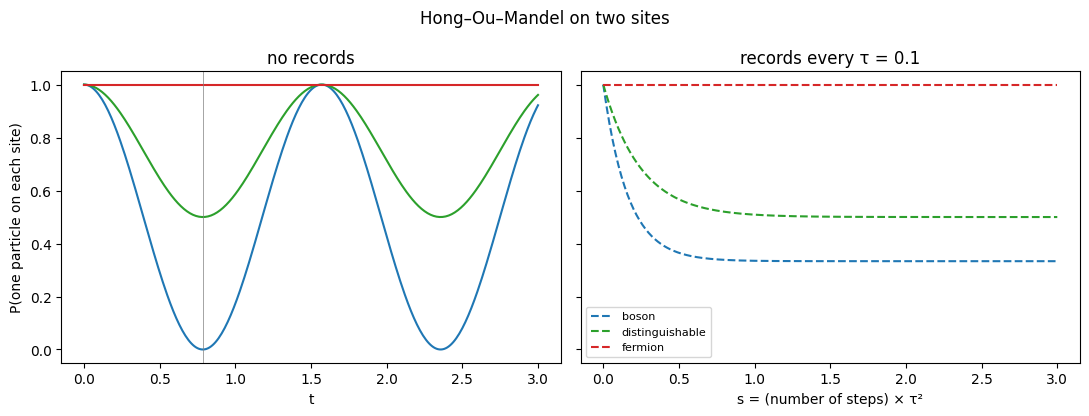

In [5]:
s = 0.6
print("max |Γ(τ)^(s/τ²) − exp(sL)| on the 4-site chain, s = 0.6")
for kind in ["boson", "distinguishable", "fermion"]:
    L, _ = classical_generator(h, 2, kind)
    errs = []
    for tau in [0.1, 0.05, 0.025]:
        G, _ = gamma(expm(-1j * h * tau), 2, kind)
        errs.append(np.abs(np.linalg.matrix_power(G, int(round(s / tau ** 2))) - expm(s * L)).max())
    print(f"  {kind:16s} τ = 0.1, 0.05, 0.025:  " + "   ".join(f"{e:.1e}" for e in errs))

h2 = chain(2)
ts = np.linspace(0, 3, 301)
tau = 0.1
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for kind, colour in [("boson", "C0"), ("distinguishable", "C2"), ("fermion", "C3")]:
    _, C2 = gamma(np.eye(2), 2, kind); a = C2.index((1, 1))
    free = [gamma(expm(-1j * h2 * t), 2, kind)[0][a, a] for t in ts]
    Gt, _ = gamma(expm(-1j * h2 * tau), 2, kind)
    p, rec = np.eye(len(C2))[:, a], []
    for n in range(301):
        rec.append(p[a]); p = Gt @ p
    ax[0].plot(ts, free, color=colour, label=kind)
    ax[1].plot(np.arange(301) * tau ** 2, rec, '--', color=colour, label=kind)
    print(f"{kind:16s}: coincidence at t = π/4 without records {free[np.argmin(abs(ts - np.pi / 4))]:.3f};"
          f"  with records every τ = {tau}, after 300 steps {rec[-1]:.3f}")
ax[0].set_xlabel('t'); ax[0].set_title('no records'); ax[0].set_ylabel('P(one particle on each site)')
ax[1].set_xlabel('s = (number of steps) × τ²'); ax[1].set_title(f'records every τ = {tau}')
ax[0].axvline(np.pi / 4, color='grey', lw=0.5); ax[1].legend(fontsize=8)
fig.suptitle('Hong–Ou–Mandel on two sites')
plt.tight_layout(); plt.show()

### 📖 In depth: reading the Hong–Ou–Mandel plot

- **Left (no records):** on two sites with hopping, the two-site system is a beam splitter whose mixing angle grows with $t$. At $t = \pi/4$ it is 50:50 and the boson coincidence hits 0.
  Distinguishable particles oscillate between 1 and 1/2. Fermions stay at 1.
- **Right (records every $\tau = 0.1$):** the dip never forms. Each step moves a little probability, the interference never accumulates, and the processes relax to their
  stationary values: 1/3 for bosons, 1/2 for distinguishable, 1 for fermions.
- **Bosons still bunch under records**: 1/3 < 1/2. That is the occupation rule (rate $m_j + 1$ into an occupied site), not interference.

The two time axes differ: real time on the left, $s = n\tau^2$ on the right (the slowed-down time of notebook 11's Zeno limit). Compare shapes and end values.

<!-- expansion:14:recap-4 -->
### 📝 Recap: section 4

- Dense records turn the three processes into classical Markov chains: inclusion (bosons), exclusion (fermions), independent walkers (distinguishable).
- The Hong–Ou–Mandel dip does not form under records; bosons still bunch (1/3 vs 1/2).


## 5. The Counting Survives: Bose–Einstein, Fermi–Dirac, Maxwell–Boltzmann

Where does each recorded process settle? Compare with one random step and no records: draw Haar-random single-particle unitaries on 3 sites and average Γ. The column from
$(1,1,0)$ is one unrecorded step; the stationary state of the averaged Γ is many recorded random steps.

Distinguishable particles land anti-bunched after one step (1/12 per double, not the Maxwell–Boltzmann 1/9; the printout's 0.085 is the 2,000-sample estimate), because both
are moved by the same $U$, whose columns are orthogonal; by section 2 this is $(1/6 + 0)/2$.

In [6]:
for N in [2, 3]:
    print(f"stationary state of the recorded process, {N} sites, 2 particles:")
    for kind in ["boson", "fermion", "distinguishable"]:
        L, C = classical_generator(chain(N), 2, kind)
        print(f"  {kind:16s}" + "  ".join(f"{c}:{p:.3f}" for c, p in zip(C, stationary(L))))

rng = np.random.default_rng(0)
Us = [unitary_group.rvs(3, random_state=rng) for _ in range(2000)]
print("\nHaar-random steps on 3 sites, 2 particles (2000 samples):")
for kind in ["boson", "fermion", "distinguishable"]:
    Gbar = np.mean([gamma(U, 2, kind)[0] for U in Us], axis=0)
    C = configurations(3, 2, kind)
    one = Gbar[:, C.index((1, 1, 0))]
    print(f"  {kind:16s} one step from (1,1,0):  " + "  ".join(f"{c}:{p:.3f}" for c, p in zip(C, one)))
    print(f"  {'':16s} many recorded steps:    " + "  ".join(f"{c}:{p:.3f}" for c, p in zip(C, stationary(Gbar - np.eye(len(C))))))

stationary state of the recorded process, 2 sites, 2 particles:
  boson           (2, 0):0.333  (1, 1):0.333  (0, 2):0.333
  fermion         (1, 1):1.000
  distinguishable (2, 0):0.250  (1, 1):0.500  (0, 2):0.250
stationary state of the recorded process, 3 sites, 2 particles:
  boson           (2, 0, 0):0.167  (1, 1, 0):0.167  (1, 0, 1):0.167  (0, 2, 0):0.167  (0, 1, 1):0.167  (0, 0, 2):0.167
  fermion         (1, 1, 0):0.333  (1, 0, 1):0.333  (0, 1, 1):0.333
  distinguishable (2, 0, 0):0.111  (1, 1, 0):0.222  (1, 0, 1):0.222  (0, 2, 0):0.111  (0, 1, 1):0.222  (0, 0, 2):0.111

Haar-random steps on 3 sites, 2 particles (2000 samples):


  boson            one step from (1,1,0):  (2, 0, 0):0.170  (1, 1, 0):0.161  (1, 0, 1):0.166  (0, 2, 0):0.170  (0, 1, 1):0.170  (0, 0, 2):0.163
                   many recorded steps:    (2, 0, 0):0.167  (1, 1, 0):0.167  (1, 0, 1):0.167  (0, 2, 0):0.167  (0, 1, 1):0.167  (0, 0, 2):0.167
  fermion          one step from (1,1,0):  (1, 1, 0):0.338  (1, 0, 1):0.329  (0, 1, 1):0.333
                   many recorded steps:    (1, 1, 0):0.333  (1, 0, 1):0.333  (0, 1, 1):0.333


  distinguishable  one step from (1,1,0):  (2, 0, 0):0.085  (1, 1, 0):0.250  (1, 0, 1):0.247  (0, 2, 0):0.085  (0, 1, 1):0.252  (0, 0, 2):0.082
                   many recorded steps:    (2, 0, 0):0.111  (1, 1, 0):0.222  (1, 0, 1):0.222  (0, 2, 0):0.111  (0, 1, 1):0.222  (0, 0, 2):0.111


### 📖 In depth: why the counting comes out

- **Detailed balance.** For bosons, the rate from $m$ to $m'$ (one particle from $i$ to $j$) is $|h|^2 m_i(m_j+1)$, and the rate back is $|h|^2 (m_j+1) m_i$: equal. So the uniform
  distribution over occupations is stationary. That is Bose–Einstein counting: each occupation pattern counts once. Fermions: same argument, uniform over patterns with no doubles.
  Distinguishable: each particle walks independently to the uniform site distribution, so each *labelled* arrangement is equally likely, and forgetting labels gives the
  multinomial weights (Maxwell–Boltzmann).
- **One unrecorded random step.** Bosons and fermions already land uniformly (a Haar-random $U$ spreads the symmetric and antisymmetric states uniformly). Distinguishable
  particles do not: both are moved by the *same* $U$, and its columns are orthogonal, so the two particles are slightly anti-bunched (1/12 per double instead of 1/9). The
  exact value follows from section 2: $\Gamma_D = (\Gamma_B + \Gamma_F)/2 = (1/6 + 0)/2$.
- **Many recorded random steps** wash that correlation out, and Maxwell–Boltzmann appears.

<!-- expansion:14:recap-5 -->
### 📝 Recap: section 5

- Recorded processes settle into Bose–Einstein, Fermi–Dirac and Maxwell–Boltzmann counting.
- One unrecorded random step already gives BE and FD for identical particles; distinguishable particles are anti-bunched until records wash it out.


## 6. The Fermion Sign Is Pure Interference

Notebook 12 showed that on an open chain, free fermions and hard-core bosons (bosons that cannot share a site) have the same Γ, while on an even ring they differ: a fermion hopping
across the closing bond passes the other particle and picks up a sign. Both have the same occupation rule (at most one per site). So the difference should be pure interference,
and division events should remove it.

(On an odd ring the two coincide exactly for two particles: the fermion sign is a π flux, which on an odd ring is gauge-equivalent to $h \to -h$, and Γ cannot tell $H$ from $-H$
for real $H$. The $N = 5$ row shows this, so it is not evidence that records erase anything.)

In [7]:
for N in [4, 5, 6]:
    Hb, _ = two_particle_hamiltonian(N, ring=True, fermion=False)
    Hf, _ = two_particle_hamiltonian(N, ring=True, fermion=True)
    free = [np.abs(np.abs(expm(-1j * Hb * t)) ** 2 - np.abs(expm(-1j * Hf * t)) ** 2).max() for t in [0.5, 1, 2, 3]]
    rec = []
    for tau in [0.1, 0.05, 0.025]:
        k = int(round(0.6 / tau ** 2))
        Gb = np.linalg.matrix_power(np.abs(expm(-1j * Hb * tau)) ** 2, k)
        Gf = np.linalg.matrix_power(np.abs(expm(-1j * Hf * tau)) ** 2, k)
        rec.append(np.abs(Gb - Gf).max())
    print(f"ring N = {N}:  no records, max |Γ_hard-core − Γ_fermion| at t = 0.5, 1, 2, 3: "
          + "  ".join(f"{x:.3f}" for x in free)
          + "    records every τ = 0.1, 0.05, 0.025: " + "  ".join(f"{x:.0e}" for x in rec))

ring N = 4:  no records, max |Γ_hard-core − Γ_fermion| at t = 0.5, 1, 2, 3: 0.178  0.952  0.877  0.880    records every τ = 0.1, 0.05, 0.025: 1e-03  3e-04  7e-05
ring N = 5:  no records, max |Γ_hard-core − Γ_fermion| at t = 0.5, 1, 2, 3: 0.000  0.000  0.000  0.000    records every τ = 0.1, 0.05, 0.025: 0e+00  0e+00  0e+00
ring N = 6:  no records, max |Γ_hard-core − Γ_fermion| at t = 0.5, 1, 2, 3: 0.011  0.194  0.957  0.442    records every τ = 0.1, 0.05, 0.025: 2e-06  1e-07  7e-09


### 📖 In depth: why records remove the ring difference

Hard-core bosons and fermions have the same configurations and the same $|H_{mn}|$; they differ only in the sign on hops across the ring's closing bond. Γ over a short step depends
on $|H_{mn}|^2$ at order $\tau^2$, so the sign is invisible there; it shows only when several hops interfere, which division events prevent. With records every $\tau$ the two processes
converge to the same exclusion process.

$N = 5$ gives zero difference even without records, the coincidence explained in notebook 12: on an odd ring, flipping every hopping sign is equivalent to the π flux the fermions see,
and for a real $H$, as here, Γ cannot tell $H$ from $-H$.

<!-- expansion:14:recap-6 -->
### 📝 Recap: section 6

- On a ring, fermions and hard-core bosons share the occupation rule and differ only by a sign.
- Without records Γ differs by up to 0.96; with dense records the difference vanishes.
- The fermion sign is pure interference.


### 🔭 Looking ahead

**Connections.**
- Notebook 11's division events and Zeno limit are the machinery of section 4: the same $\tau^2$ scaling turns Γ into a Markov rate.
- Notebook 12: the fermion sign as a stoquasticity question. Here the same sign is shown to be pure interference.
- Notebook 13: Γ forgets the momentum; here Γ forgets the labels. In both, what is forgotten is where the indivisibility can hide.
- Next on the backlog, item 5 (Aharonov–Bohm and Berry phase): another phase that Γ sees only through interference around a loop.

**Possible extensions.** Partial records (the $\varepsilon$ of notebook 11) to interpolate the Hong–Ou–Mandel dip; energies on the sites to get thermal counting; three or more bosons
(boson sampling).

**Prior work (checked 2026-10-29).**
- Hong, Ou & Mandel, Phys. Rev. Lett. 59, 2044 (1987).
- Symmetric inclusion process: three separate papers, Giardinà, Kurchan and Redig (2007), Giardinà et al. (2009) and Giardinà, Redig and Vafayi (2010).
- Dephased free particles → symmetric exclusion and inclusion processes: known (Yamaga (2020); Wellnitz et al. (2022), App. E). Bernard–Jin (2019) is the related
  noisy-hopping model ("quantum SSEP"); see also Eisler (2011).
- The uniform landing of bosons after a Haar-random step: standard (the symmetric subspace is irreducible under the unitary group, so the Haar average is uniform). It underlies
  the bosonic birthday paradox: Aaronson and Arkhipov (2011), §13, quote the two-boson "1/2 with classical balls, but 2/3 if … identical bosons" example as well known (their Theorem 72
  is the collision bound, not uniformity); Arkhipov and Kuperberg (2012) treat bosons in the uniform mixed state.
- The flux-dependent part of the exchange term, $X(\Phi) - X(0)$, is order τ^ℓ with ℓ the loop length, ∝ sin Φ for odd ℓ and ∝ (1 − cos Φ) for even ℓ: checked in a side
  calculation (not printed in this notebook) on rings of ℓ = 3, 4, 5, 6 sites (log-log slopes 2.97, 3.98, 4.98, 5.98). It beats the flux-free τ⁴ only on triangles.

## Summary

- **Γ generically knows the statistics** (not for every $U$: a $U$ that only permutes sites or adds phases gives the same Γ on distinct-site columns), and the Hong–Ou–Mandel effect is one column of it: coincidence 0 for bosons, 1/2 for distinguishable particles, 1 for fermions.
- **For two particles, distinguishable is exactly the average**, $\Gamma_D = (\Gamma_B + \Gamma_F)/2$, on every column that starts from two distinct sites, so there bosons and
  fermions differ from it by $\pm X$, the exchange term.
- **The statistics has two parts that scale differently.**
  - The **occupation rule** (Pauli exclusion; the Bose factor $m+1$) changes entries of order $\tau^2$.
  - **Exchange interference** between *different* configurations with distinct sites (off-diagonal entries) is of order $\tau^4$, unless a flux threads a 3-site loop: on a triangle
    with Φ = π/3 or π/2 it is of order $\tau^3$ (∝ sin Φ). Chains, Φ = 0 or π, and 4- and 5-site rings give $\tau^4$. Either way it is smaller than the $\tau^2$ rule.
  - The two parts are not separate terms of $X$. On the rows that join an occupied site, $X$ itself is order $\tau^2$: there the two stories have the same amplitude and always
    add in phase, so Bose enhancement is exchange interference that is always constructive. The diagonal $X$ is also order $\tau^2$ but negative for bosons. It is the mirror
    image of the join rows (each column of $X$ sums to zero): bosons leave a distinct-site configuration faster because they can join. What records erase is the off-diagonal,
    distinct-to-distinct part.
- **Division events separate them.** Dense records turn the three processes into classical Markov chains: exclusion (fermions), inclusion (bosons), independent walkers
  (distinguishable). The interference, including the Hong–Ou–Mandel dip and the fermion sign around a ring, is erased; Pauli exclusion and Bose bunching survive as rate rules.
- **The counting survives too.** The recorded processes settle into Bose–Einstein (every occupation equally likely), Fermi–Dirac, and Maxwell–Boltzmann counting. For identical
  particles one unrecorded random step already gives the same counting; distinguishable particles need the records to reach Maxwell–Boltzmann.
- **So, in ISP terms:** the part of quantum statistics that survives division events is a rule about the configuration space and the rates between configurations, not a force (Griffiths).
  The part that does not survive, the exchange interference, lives only in indivisible stretches of the process.

Caveats: two (and one three-) particle examples on small lattices; free particles only; degenerate sites (no energy differences), so the counting is "microcanonical".

Prior work: Hong–Ou–Mandel (1987) is the beam-splitter column. The classical limits are the symmetric exclusion process and the symmetric inclusion process (Giardinà, Kurchan
and Redig (2007); Giardinà et al. (2009); Giardinà, Redig and Vafayi (2010)), and that dephased free particles become them is known (Yamaga (2020); Wellnitz et al. (2022), App. E;
see also Bernard–Jin (2019) for noisy hopping). The uniform landing of bosons after a Haar-random step is standard (the symmetric subspace is irreducible under the unitary group);
it underlies the bosonic birthday paradox (Aaronson and Arkhipov (2011), §13, which quotes the two-boson 1/2-vs-2/3 example; Arkhipov and Kuperberg (2012)). Division events are
Barandes's (Paper 3 §2.2). The ISP reading (rule survives records, interference does not) restates these in Γ language.

### 📖 In depth: the one-paragraph version

On occupation configurations, Γ for bosons, fermions and distinguishable particles is built from permanents, determinants and products of probabilities. For two particles starting on distinct sites,
distinguishable is exactly the average of the other two, so the difference is one exchange term. At short times the occupation rule (Pauli exclusion, Bose factor $m+1$) changes
Γ at order $\tau^2$, while exchange interference between different distinct-site configurations is order $\tau^4$ (order $\tau^3$ only if a flux threads a 3-site loop); on the join rows the exchange term is the τ² rule itself, always constructive. Dense division events therefore keep the rule and erase the interference: the three
processes become classical exclusion, inclusion and independent walks, which settle into Fermi–Dirac, Bose–Einstein and Maxwell–Boltzmann counting. The Hong–Ou–Mandel dip
and the fermion sign around a ring disappear under records; bunching and exclusion do not. Griffiths' "not really a force" is literal here: what survives is a rule about configurations.

<!-- expansion:14:check -->
### 📝 Check your understanding

1. *Why is the boson coincidence at the beam splitter exactly 0?*
   The two stories (both transmitted, both reflected) have equal size and opposite sign, and bosons add amplitudes.
2. *Does looking at the particles constantly stop bosons from bunching?*
   No. It stops the Hong–Ou–Mandel dip (interference), but the rate into an occupied site is still $m_j+1$, so bosons still bunch (1/3 vs 1/2 on two sites).
3. *What does a division event do to the fermion sign around a ring?*
   Erases its effect: fermions and hard-core bosons become the same exclusion process.
4. *Where does Bose–Einstein counting come from in this picture?*
   Detailed balance of the recorded boson process: the rate from $m$ to $m'$ equals the rate back, so every occupation pattern is equally likely.
5. *In what sense is the exchange force "not really a force"?*
   What survives records is a rule about which configurations can be entered and how fast. Nothing pushes; the configuration space and its rates differ.
